# Dependances

In [355]:
from sklearn.model_selection import train_test_split
#from sklearn.preprocessing import MinMaxScaler
#from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import RobustScaler
#from tensorflow.keras.models import Sequential
#from tensorflow.keras.layers import LSTM, Dropout, Dense, BatchNormalization
#from tensorflow.keras.callbacks import EarlyStopping

#import tensorflow as tf
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from sklearn.preprocessing import StandardScaler

device = torch.device("cuda")  # Définit le GPU comme appareil

# Data

- 400+ cryptos, 1 minute resolution : https://www.kaggle.com/datasets/tencars/392-crypto-currency-pairs-at-minute-resolution?resource=download

In [356]:
df = pd.read_csv('datams.csv')

Suppression des crypto's avec moins d'[Hours] heures de données

In [357]:
hours = 48

block_counts = df.groupby('crypto')['block'].count()
print(sum(block_counts < hours)) #1 mois c'est 43 200

#cryptos_to_drop = block_counts[block_counts < hours].index
#df = df[~df["crypto"].isin(cryptos_to_drop)]

#print(f"Nombre de cryptos supprimées : {len(cryptos_to_drop)}")
#print(f"Taille du DataFrame filtré : {df.shape}")

0


# Entrainement Transformer

## Embedding

Nous devons creer des embedding afin d'apprendre au modele que chaque crypto peut agir d'une maniere différente

### Attribution d'un ID unique à chaque paire

In [358]:
crypto_mapping = {crypto: idx for idx, crypto in enumerate(df['crypto'].unique())}

df['crypto_id'] = df['crypto'].map(crypto_mapping)
df.head()

,crypto,block,open,close,high,low,volume,crypto_id
0,1inch-usd,1.628984e+12,3.0473,3.0337,3.0473,3.0256,1181.533217,0
1,1inch-usd,1.628987e+12,3.0242,3.0375,3.0375,3.0065,27.623659,0
2,1inch-usd,1.628991e+12,3.0580,3.0811,3.0845,3.0580,27.753915,0
3,1inch-usd,1.628994e+12,3.0694,3.0607,3.0694,3.0586,86.379213,0
4,1inch-usd,1.628998e+12,3.0068,3.0266,3.0266,3.0053,631.110223,0


### Standardisation et séparation des données

By normalizing the data after splitting, we maintain the integrity of the testing set as an unbiased evaluation metric.

In [359]:
scaler_training = RobustScaler()
scaler_test = RobustScaler() #permet de ne pas s'adapter en amont aux données de test

indices = df.index.values
train_indices, test_indices = train_test_split(indices, test_size=0.2, random_state=42, shuffle=False)

# Sélectionner les ensembles d'entraînement et de test à partir des indices
X_train = df.loc[train_indices, ['open', 'high', 'low', 'volume']].values
X_test = df.loc[test_indices, ['open', 'high', 'low', 'volume']].values

y_train = df.loc[train_indices, 'close'].values
y_test = df.loc[test_indices, 'close'].values

X_train_scaled, y_train_scaled = scaler_training.fit_transform(X_train), scaler_test.fit_transform(y_train.reshape(-1, 1))
X_test_scaled,y_test_scaled = scaler_training.transform(X_test), scaler_test.transform(y_test.reshape(-1, 1))

#tensor
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32).to(device)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32).to(device)
y_train_tensor = torch.tensor(y_train_scaled, dtype=torch.float32).to(device)
y_test_tensor = torch.tensor(y_test_scaled, dtype=torch.float32).to(device)

# Création de la couche d'embedding
crypto_embedding = nn.Embedding(num_embeddings=len(crypto_mapping), embedding_dim=16).to(device)

# Identifiants des cryptos
crypto_ids_train = torch.tensor(df.loc[train_indices, 'crypto_id'].values, dtype=torch.long).to(device)
crypto_ids_test = torch.tensor(df.loc[test_indices, 'crypto_id'].values, dtype=torch.long).to(device)

# Association des embeddings aux ID's
embedded_cryptos_train = crypto_embedding(crypto_ids_train)
embedded_cryptos_test = crypto_embedding(crypto_ids_test)

# Concaténer les données normalisées avec les embeddings
X_train_final = torch.cat([X_train_tensor, embedded_cryptos_train], dim=1)
X_test_final = torch.cat([X_test_tensor, embedded_cryptos_test], dim=1)

print(crypto_embedding.weight.shape)
print(X_train_final.size())
print(X_test_final.size())

torch.Size([760, 16])
torch.Size([921811, 20])
torch.Size([230453, 20])


## Construction du modèle

In [360]:
class CryptoPredictor(nn.Module):
    def __init__(self, input_dim, hidden_dim):
        super(CryptoPredictor, self).__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.dropout = nn.Dropout(0.3)
        self.relu1 = nn.ReLU()
        self.fc2 = nn.Linear(hidden_dim, hidden_dim)
        self.dropout = nn.Dropout(0.2)
        self.relu2 = nn.ReLU()
        self.fc3 = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        x = self.fc1(x)
        x = self.dropout(x)
        x = self.relu1(x)
        x = self.fc2(x)
        x = self.dropout(x)
        x = self.relu2(x)
        x = self.fc3(x)
        return x

In [361]:
input_dim = X_train_final.shape[1]  # Nb de features + embedding_dim
hidden_dim = 32                     # Vous pouvez ajuster

model = CryptoPredictor(input_dim=input_dim, hidden_dim=hidden_dim)
print(model)

CryptoPredictor(
  (fc1): Linear(in_features=20, out_features=32, bias=True)
  (dropout): Dropout(p=0.2, inplace=False)
  (relu1): ReLU()
  (fc2): Linear(in_features=32, out_features=32, bias=True)
  (relu2): ReLU()
  (fc3): Linear(in_features=32, out_features=1, bias=True)
)


In [362]:
criterion = nn.MSELoss() # Fonction de perte
optimizer = torch.optim.Adam(model.parameters(), lr=0.0001, weight_decay=1e-4) # Optimiseur

In [363]:
num_epochs = 100
batch_size = 64

model.to(device)
for epoch in range(num_epochs):
    model.train()
    optimizer.zero_grad()
    predictions = model(X_train_final)
    loss = criterion(predictions, y_train_tensor)
    loss.backward(retain_graph=True)
    optimizer.step()

    # Afficher la perte pour chaque époque
    print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {loss.item():.4f}")

KeyboardInterrupt: 

In [346]:
print("Mean of y_train_scaled:", y_train_scaled.mean())
print("Std of y_train_scaled:", y_train_scaled.std())

print("Mean of x_train_scaled:", X_train_scaled.mean())
print("Std of x_train_scaled:", X_train_scaled.std())


Mean of y_train_scaled: 1297.517403222553
Std of y_train_scaled: 14396.341410398516
Mean of x_train_scaled: 997.4261533644409
Std of x_train_scaled: 13004.443053301562


In [347]:
# Mettre le modèle en mode évaluation
model.eval()

# Calculer les prédictions sur le test
with torch.no_grad():
    test_predictions = model(X_test_final)
    test_loss = criterion(test_predictions, y_test_tensor)

print(f"Test Loss: {test_loss.item():.4f}")

Test Loss: 95036.9922


In [348]:
from sklearn.metrics import r2_score

test_predictions = test_predictions.cpu().detach().numpy()
y_test_original = scaler_test.inverse_transform(y_test_tensor.cpu().detach().numpy())

r2 = r2_score(y_test_original, test_predictions)
print(f"R^2 Score: {r2:.4f}")

R^2 Score: -0.0432


In [349]:
from sklearn.metrics import mean_absolute_error
mae = mean_absolute_error(y_test_original, test_predictions)
print(f"Mean Absolute Error: {mae:.4f}")


Mean Absolute Error: 2100.0493


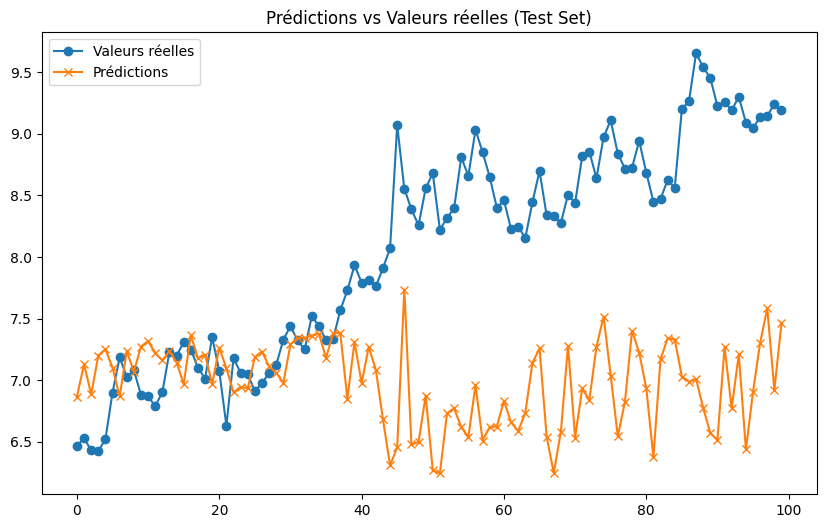

In [350]:
if isinstance(test_predictions, torch.Tensor):
    test_predictions_numpy = test_predictions.cpu().numpy()  # Convertir en NumPy si nécessaire
else:
    test_predictions_numpy = test_predictions

if isinstance(y_test_tensor, torch.Tensor):
    y_test_numpy = y_test_tensor.cpu().numpy()  # Convertir en NumPy si nécessaire
else:
    y_test_numpy = y_test_tensor

# Inverser la normalisation pour les données originales
test_predictions_original = scaler_test.inverse_transform(test_predictions_numpy)
y_test_original = scaler_test.inverse_transform(y_test_numpy)

# Tracer les valeurs réelles vs prédictions
plt.figure(figsize=(10, 6))
plt.plot(y_test_original[:100], label='Valeurs réelles', marker='o')  # Les 100 premières valeurs réelles
plt.plot(test_predictions_original[:100], label='Prédictions', marker='x')  # Les 100 premières prédictions
plt.legend()
plt.title("Prédictions vs Valeurs réelles (Test Set)")
plt.show()


# LSTM

In [351]:
w_size = 48

'''Fonction pour créer des séquences temporelles de plusieurs heure'''

def create_sequences(data, target, w_size):

    sequences, targets = [], []
    for i in range(len(data) - w_size):
        sequences.append(data[i:i+w_size]) #X
        targets.append(target[i+w_size]) #Y
    return np.array(sequences), np.array(targets)

#
X = df[['open', 'close', 'high', 'low']].values
y = df['close'].values  # Target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

scaler_x, scaler_y = MinMaxScaler(), MinMaxScaler()

X_train, y_train  = scaler_x.fit_transform(X_train), scaler_y.fit_transform(y_train.reshape(-1, 1)).flatten()
X_test, y_test = scaler_x.transform(X_test), scaler_y.transform(y_test.reshape(-1, 1)).flatten()

X_train_seq, y_train_seq = create_sequences(X_train, y_train, w_size)
X_test_seq, y_test_seq = create_sequences(X_test, y_test, w_size)

print(f"X_train_seq shape: {X_train_seq.shape}, X_test_seq shape: {X_test_seq.shape}")
print(f"y_train_seq shape: {y_train_seq.shape}, y_test_seq shape: {y_test_seq.shape}")

NameError: name 'MinMaxScaler' is not defined

In [49]:
print("GPU est disponible :", tf.config.list_physical_devices('GPU'))

NameError: name 'tf' is not defined

In [ ]:
input_shape=(X_train_seq.shape[1], X_train_seq.shape[2])

model = Sequential([
        LSTM(64, return_sequences=True, input_shape=input_shape),
        Dropout(0.2),
        LSTM(128, return_sequences=True),
        Dropout(0.2),
        LSTM(256, return_sequences=True),
        Dense(128, activation='tanh'),
        LSTM(64, return_sequences=False),
        Dense(32, activation='tanh'),
        Dense(1)  # Sortie
])

model.compile(optimizer='adam', loss='huber_loss', metrics=['mae']) #ou RMSprop
model.summary()

In [ ]:
history = model.fit(
    X_train_seq, y_train_seq,
    epochs=2,
    batch_size=64,
    validation_data=(X_test_seq, y_test_seq),
    verbose=1,
    callbacks=[EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)]
)